# TP2 - Parte 1: dataset y preprocesamiento

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Tiene que poder leerse como un informe: celdas Markdown que explican qué se hace y por qué,
código y salidas (gráficos y tablas) **ejecutadas y guardadas**. Una notebook sin salidas
visibles se considera no entregada.

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.

**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno 1 :
- Alumno 2 :

## 1. Entorno

La notebook se ejecuta localmente desde la raíz del repositorio (entorno `cv2-venv`, con GPU), donde ya
están el dataset y los resultados intermedios. Si se abre en Colab, la celda siguiente clona el repositorio
e instala lo que falta; localmente no hace nada.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Completar con la URL del fork si se ejecuta en Colab.
    REPO_URL = "https://github.com/<usuario>/tuia-dog-recognition-app.git"
    !git clone $REPO_URL proyecto
    %cd proyecto
    !pip install -q pydantic-settings python-dotenv kagglehub albumentations imagehash ultralytics
print("Colab:", IN_COLAB)

Colab: False


## 2. Configuración

Las rutas se fijan como variables de entorno **antes** de importar `lib`: `src/.env` usa rutas relativas a
`src/` (es la configuración del backend local) y la notebook corre desde la raíz. Sin pgvector: esta notebook
no usa la base vectorial.

In [2]:
import logging
import os
from pathlib import Path

ROOT = Path.cwd()
assert (ROOT / "src" / "lib").is_dir(), "Ejecutar la notebook desde la raiz del repositorio"
os.environ.update(
    {
        "USE_PGVECTOR": "false",
        "DATA_PATH": str(ROOT / "data"),
        "DATASET_PATH": str(ROOT / "data" / "dataset"),
        "OUTPUT_PATH": str(ROOT / "output"),
        "MODEL_PATH": str(ROOT / "models"),
        "TORCH_HOME": str(ROOT / "models" / "torch"),
        "YOLO_MODEL": str(ROOT / "models" / "yolov8n.pt"),
    }
)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from lib.config import settings

logging.getLogger().setLevel(logging.WARNING)  # config.py configura INFO; en la notebook solo avisos
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 140)

DATASET = settings.dataset_path
SPLITS_DIR = settings.data_path / "splits"
CACHE = settings.output_path / "p1"  # mediciones intermedias, fuera de git
SEED = 42

print("dataset:", DATASET)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no")

dataset: c:\Users\lucas\Documents\TUIA\IA 5.1 - Vision por Computadora\tuia-dog-recognition-app\data\dataset
GPU: NVIDIA GeForce GTX 1050


## 3. Dataset

Se descarga con `scripts/download_dataset.py` (requiere credenciales de Kaggle) solo si no está.

In [3]:
if not (DATASET / "dogs.csv").exists():
    !python scripts/download_dataset.py
print(sorted(p.name for p in DATASET.iterdir() if not p.name.startswith(".")))

['dogs.csv', 'independent', 'independent_candidates', 'test', 'train', 'valid']


## 4. Descripción del dataset

**70 Dog Breeds-Image Data Set** (Kaggle, `gpiosenka/70-dog-breedsimage-data-set`), publicado por Gerry
(versión 2, julio de 2021). Según su descripción, las imágenes se obtuvieron con búsquedas por raza en
internet, el autor las revisó a mano para quitar las incorrectas y duplicadas, y las redimensionó a
224 x 224 x 3 en JPG. Viene dividido en `train/`, `valid/` y `test/` con una carpeta por raza, más
`dogs.csv` con ruta, etiqueta y split de cada imagen.

**Licencia:** CC0 (dominio público), según los metadatos del dataset en Kaggle. Permite el uso académico que
le damos. Matiz: CC0 lo declara quien armó el dataset, pero las fotos salen de búsquedas web y no se
documenta la licencia de cada foto original (ver sección 12).

El manifiesto `data/splits/splits_v0.csv` es `dogs.csv` normalizado (ruta, raza, split); es el punto de
partida de todo el análisis. Las razas se normalizan quitando espacios repetidos en el nombre.

In [4]:
from lib.dataset.manifest import class_names, load_manifest

v0 = load_manifest(SPLITS_DIR / "splits_v0.csv", dataset_path=DATASET, check_files=True)
summary = v0.groupby("split").agg(imagenes=("path", "size"), razas=("breed", "nunique")).reindex(["train", "valid", "test"])
summary.loc["total"] = [len(v0), v0["breed"].nunique()]
display(summary)
print("Razas:", len(class_names(v0)))
print(", ".join(class_names(v0)))

,imagenes,razas
split,,
train,7946,70
valid,700,70
test,700,70
total,9346,70


Razas: 70
Afghan, African Wild Dog, Airedale, American Hairless, American Spaniel, Basenji, Basset, Beagle, Bearded Collie, Bermaise, Bichon Frise, Blenheim, Bloodhound, Bluetick, Border Collie, Borzoi, Boston Terrier, Boxer, Bull Mastiff, Bull Terrier, Bulldog, Cairn, Chihuahua, Chinese Crested, Chow, Clumber, Cockapoo, Cocker, Collie, Corgi, Coyote, Dalmation, Dhole, Dingo, Doberman, Elk Hound, French Bulldog, German Sheperd, Golden Retriever, Great Dane, Great Perenees, Greyhound, Groenendael, Irish Spaniel, Irish Wolfhound, Japanese Spaniel, Komondor, Labradoodle, Labrador, Lhasa, Malinois, Maltese, Mex Hairless, Newfoundland, Pekinese, Pit Bull, Pomeranian, Poodle, Pug, Rhodesian, Rottweiler, Saint Bernard, Schnauzer, Scotch Terrier, Shar_Pei, Shiba Inu, Shih-Tzu, Siberian Husky, Vizsla, Yorkie


### 4.1 Mediciones que usan las secciones siguientes

Se mide una vez cada imagen y se guarda en `output/p1/` (fuera de git):

- **Calidad**: resolución, canales, nitidez (varianza del Laplaciano), brillo, contraste y pHash.
- **Embeddings** del baseline de la Etapa 1 (ResNet50 ImageNet, el mismo `BaselineEmbedder` de la app):
  sirven para encontrar razas fáciles de confundir y casi-duplicados.
- **YOLO** preentrenado en COCO (`yolov8n`, el detector de la Etapa 3): cuántos perros, personas o gatos
  detecta y qué fracción de la imagen ocupa el perro.

YOLO se corre con `imgsz=320`. Con el valor por defecto de ultralytics (640) las imágenes de 224 px se
agrandan casi 3 veces y la detección empeora mucho: en una muestra de 600 imágenes detectó un perro en el
54,5 % a 640 contra el 84,5 % a 320 (y a 640 confundió perros con gatos en el 9,2 %). Es un dato a tener en
cuenta en la Etapa 3 cuando la imagen de entrada es chica.

In [5]:
from lib.dataset.cleaning import load_or_compute_measurements
from lib.dataset.eda import run_yolo_framing

YOLO_EDA_IMGSZ = 320

quality, embeddings = load_or_compute_measurements(v0, DATASET, CACHE, settings.image_size)

yolo_path = CACHE / "yolo_eda.csv"
if yolo_path.exists():
    yolo = pd.read_csv(yolo_path)
else:
    yolo = run_yolo_framing(
        [DATASET / p for p in v0["path"]],
        Path(settings.yolo_model),
        conf=settings.yolo_conf_threshold,
        iou=settings.yolo_iou_threshold,
        imgsz=YOLO_EDA_IMGSZ,
        device=0 if torch.cuda.is_available() else "cpu",
    )
    yolo.insert(0, "path", v0["path"].to_numpy())
    yolo.to_csv(yolo_path, index=False)
assert yolo["path"].tolist() == v0["path"].tolist()
yolo = yolo.assign(breed=v0["breed"].to_numpy(), split=v0["split"].to_numpy())
print("calidad:", quality.shape, "| embeddings:", embeddings.shape, "| yolo:", yolo.shape)

calidad: (9346, 14) | embeddings: (9346, 2048) | yolo: (9346, 9)


### 4.2 Encuadre de las imágenes y comparación con los recortes de YOLO

En la Etapa 3 el clasificador no recibe fotos como estas sino **recortes** que produce YOLO sobre fotos
arbitrarias. Para comparar, se mide qué fracción de cada imagen del dataset ocupa la caja del perro más
grande que detecta YOLO.

Imagenes con al menos un perro detectado: 7836 de 9346 (83.8%)


,count,mean,std,min,5%,25%,50%,75%,95%,max
dog_area_frac,7836.0,0.881,0.121,0.112,0.632,0.846,0.919,0.961,0.992,0.999
dog_box_aspect,7836.0,0.975,0.105,0.293,0.789,0.943,0.993,1.021,1.102,2.039


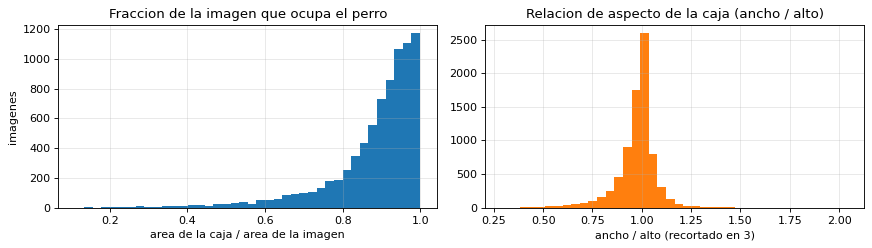

In [6]:
with_dog = yolo[yolo["n_dogs"] > 0]
print(f"Imagenes con al menos un perro detectado: {len(with_dog)} de {len(yolo)} ({len(with_dog) / len(yolo):.1%})")
display(with_dog[["dog_area_frac", "dog_box_aspect"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(with_dog["dog_area_frac"], bins=40, color="tab:blue")
axes[0].set(title="Fraccion de la imagen que ocupa el perro", xlabel="area de la caja / area de la imagen", ylabel="imagenes")
axes[1].hist(with_dog["dog_box_aspect"].clip(0, 3), bins=40, color="tab:orange")
axes[1].set(title="Relacion de aspecto de la caja (ancho / alto)", xlabel="ancho / alto (recortado en 3)")
fig.tight_layout()
plt.show()

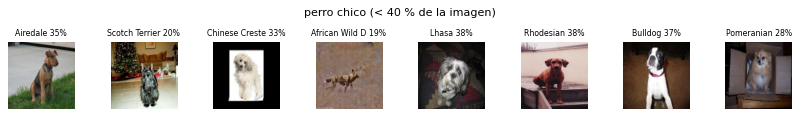

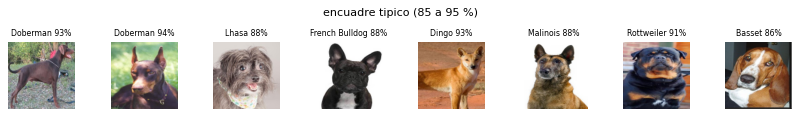

In [7]:
from lib.visualization.grid import show_grid

rng = np.random.default_rng(SEED)
groups = {
    "perro chico (< 40 % de la imagen)": with_dog[with_dog["dog_area_frac"] < 0.40],
    "encuadre tipico (85 a 95 %)": with_dog[with_dog["dog_area_frac"].between(0.85, 0.95)],
}
for label, frame in groups.items():
    sample = frame.sample(8, random_state=SEED)
    show_grid([DATASET / p for p in sample["path"]], [f"{b[:14]} {a:.0%}" for b, a in zip(sample["breed"], sample["dog_area_frac"])], cols=8, suptitle=label)
    plt.show()

**Lectura.** El dataset ya está muy "recortado": en la mitad de las imágenes el perro ocupa más del 90 % y
casi siempre hay un solo perro, centrado y en pose de foto. En ese sentido se parece a un recorte de YOLO,
pero hay diferencias que constituyen un **cambio de dominio** para la Etapa 3:

- **Resolución**: todas las imágenes son de 224 x 224. Un recorte de YOLO tiene la resolución del perro en la
  foto original: un perro chico o lejano da un recorte de pocos píxeles que hay que agrandar (pierde detalle),
  y uno grande da más detalle que el dataset.
- **Relación de aspecto**: en el dataset las cajas son casi cuadradas (mediana de ancho/alto 0,99) porque
  las imágenes son cuadradas y el perro las llena. En fotos reales la caja de YOLO toma la forma del perro
  (alargada si está de perfil o acostado). El preprocesamiento compartido conserva la proporción y rellena
  (padding) en lugar de estirar, para no deformar al perro.
- **Contenido del recorte**: la caja puede cortar patas o cabeza, o incluir parte de otro perro o de una
  persona; el dataset casi no tiene esos casos. La augmentation agrega recortes aleatorios desde los bordes
  para simularlo (sección 9).
- **Fotos no curadas**: el dataset tiene fotos elegidas a mano, en general de buena calidad. El conjunto
  independiente (sección 7) mide cuánto cae el rendimiento fuera de ese dominio.

### 4.3 Limitaciones del dataset

- **Razas muy parecidas** entre sí (Lhasa y Shih-Tzu, Boston Terrier y Bulldog, Cockapoo y Labradoodle,
  Border Collie y Collie, entre otras; se miden en la sección 5.3): son las que más va a confundir cualquier
  modelo.
- **Etiquetas inconsistentes y copias**: el control de calidad (sección 6) encontró la misma foto con dos
  razas distintas, cientos de duplicados dentro de `train` y, sobre todo, copias de imágenes de `train` en
  `valid` y `test` (fuga de datos). Sin limpiarlas, las métricas de `test` quedan infladas.
- **Sesgo de origen web**: son fotos de búsquedas de internet, muchas de perros de exposición, posados, con
  fondos limpios o blancos y buena iluminación. No representan fotos de celular de perros en la calle.
- **Taxonomía y mestizos**: no hay mestizos en general, pero sí dos cruzas "de diseño" (Cockapoo y
  Labradoodle), y hay categorías que no son razas independientes (Blenheim es una variedad de color del
  Cavalier King Charles). Un perro mestizo o de una raza fuera de las 70 va a recibir igual alguna de las 70:
  por eso la Etapa 1 tiene un umbral para responder "unknown".
- **Resolución baja (224 x 224)**: limita los detalles finos (textura del pelo, forma de las orejas) y obliga a
  agrandar las imágenes para el detector.
- **Tamaño**: unas 100 imágenes por raza en `train` y 10 en `valid` y `test`; las métricas por raza son
  ruidosas (sección 5.1).

## 5. Análisis exploratorio (EDA)

### 5.1 Distribución de clases

Imágenes por raza en cada split del dataset original (`splits_v0`).

,sum,mean,median,min,max,std,max_over_min
split,,,,,,,
train,7946.0,113.51,111.5,65.0,198.0,24.68,3.05
valid,700.0,10.00,10.0,10.0,10.0,0.00,1.00
test,700.0,10.00,10.0,10.0,10.0,0.00,1.00


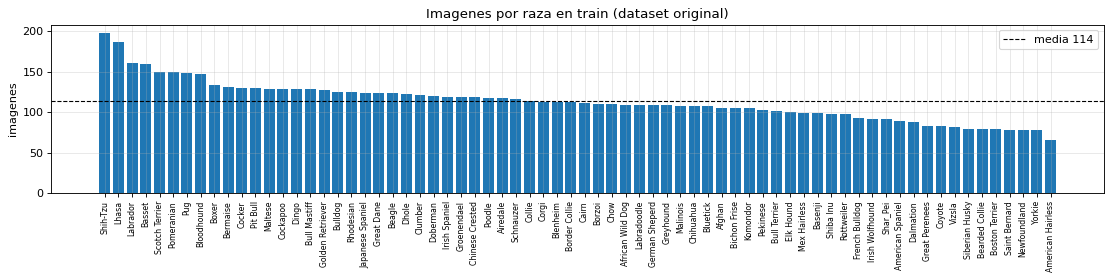

Razas con menos imagenes en train: {'Boston Terrier': 79, 'Saint Bernard': 78, 'Newfoundland': 78, 'Yorkie': 78, 'American Hairless': 65}
Razas con mas imagenes en train: {'Shih-Tzu': 198, 'Lhasa': 187, 'Labrador': 161, 'Basset': 159, 'Scotch Terrier': 150}
valid y test: exactamente [10] y [10] imagenes por raza


In [8]:
from lib.dataset.eda import class_counts, split_statistics, wilson_interval

counts = class_counts(v0)
display(split_statistics(counts))

order = counts["train"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.bar(order.index, order.to_numpy(), color="tab:blue")
ax.axhline(order.mean(), color="black", linestyle="--", linewidth=1, label=f"media {order.mean():.0f}")
ax.set(title="Imagenes por raza en train (dataset original)", ylabel="imagenes")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.legend()
fig.tight_layout()
plt.show()
print("Razas con menos imagenes en train:", order.tail(5).to_dict())
print("Razas con mas imagenes en train:", order.head(5).to_dict())
print("valid y test: exactamente", counts["valid"].unique(), "y", counts["test"].unique(), "imagenes por raza")

In [9]:
# Que precision tienen las metricas con 10 imagenes por raza y con 700 en total.
low, high = wilson_interval(8, 10)
print(f"Accuracy por raza 8/10 = 0,80 -> IC95 de Wilson [{low:.2f}, {high:.2f}] (ancho {high - low:.2f})")
p, n = 0.90, 700
se = (p * (1 - p) / n) ** 0.5
print(f"Accuracy global 0,90 con n = {n} -> error estandar {se:.3f}, IC95 aproximado +-{1.96 * se:.3f}")

Accuracy por raza 8/10 = 0,80 -> IC95 de Wilson [0.49, 0.94] (ancho 0.45)
Accuracy global 0,90 con n = 700 -> error estandar 0.011, IC95 aproximado +-0.022


**Desbalance.** `train` tiene entre 65 y 198 imágenes por raza (unas 3 veces de diferencia), mientras que
`valid` y `test` tienen exactamente 10 por raza. El desbalance de `train` puede sesgar al clasificador hacia las
razas con más imágenes; se evalúan pesos de clase al entrenar (Etapa 2). Como `valid` y `test` están
balanceados, la accuracy y las métricas macro casi coinciden.

**¿Alcanzan `valid` y `test`?** Para métricas **agregadas** sí: con 700 imágenes, una accuracy de 0,90 se
estima con un intervalo de unos +-2 puntos, suficiente para comparar modelos. Para métricas **por raza** no:
con 10 imágenes, un 8/10 tiene un intervalo de confianza que va de 0,49 a 0,94. Las métricas por raza se
reportan como descriptivas, no para sacar conclusiones raza por raza. Además, la limpieza (sección 6) obliga a
redefinir `valid` y `test` por la fuga de datos (sección 10).

### 5.2 Resoluciones, formato y archivos

Se leyó cada imagen con OpenCV y se verificó con PIL (detecta archivos truncados).

In [10]:
print("Extensiones:", v0["path"].str.rsplit(".", n=1).str[-1].str.lower().value_counts().to_dict())
print("Archivos ilegibles o corruptos:", int((~quality["readable"].astype(bool)).sum()))
res = quality.groupby(["height", "width", "channels"]).size().rename("imagenes").reset_index()
res["relacion_de_aspecto"] = res["width"] / res["height"]
display(res)

Extensiones: {'jpg': 9346}
Archivos ilegibles o corruptos: 0


,height,width,channels,imagenes,relacion_de_aspecto
0,224,224,3,9346,1.0


Todas las imágenes son JPG de 224 x 224 con 3 canales (RGB; ninguna en escala de grises) y ninguna está
corrupta: la distribución de ancho x alto y de relación de aspecto es un único punto (1:1), porque el autor
las redimensionó a ese tamaño. Ese redimensionado ya **estiró** las fotos originales no cuadradas: algunas
razas pueden verse levemente deformadas y no hay forma de recuperarlo.

### 5.3 Muestra visual y razas fáciles de confundir

Un ejemplo de cada raza (`train`):

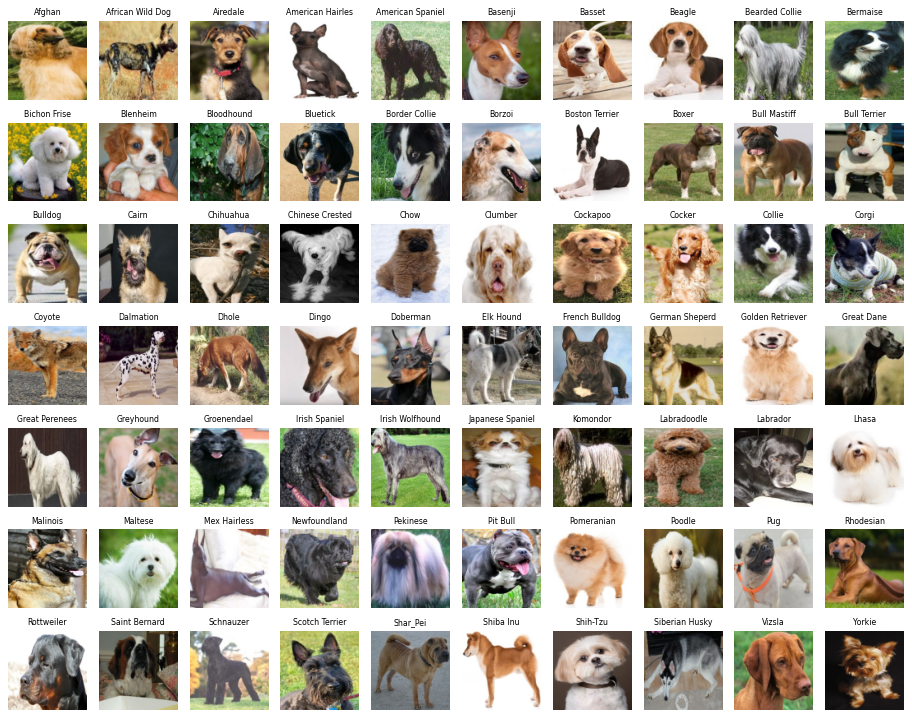

In [11]:
breeds = class_names(v0)
first = v0[v0["split"] == "train"].groupby("breed")["path"].first().reindex(breeds)
show_grid([DATASET / p for p in first], [b[:16] for b in breeds], cols=10, size=96, cell_inches=1.15, title_fontsize=7)
plt.show()

Para medir qué razas se confunden se usa el espacio de embeddings del baseline (ResNet50 de ImageNet, el
mismo de la Etapa 1): para cada imagen de `train` se busca su vecino más cercano (similitud coseno) y se cuenta
cuántas veces es de otra raza. Es exactamente el error que va a cometer la búsqueda por similitud. Se usa
`train` **ya limpio** (`splits_v1`, sección 10): con los duplicados, el vecino más cercano de una imagen sería
su propia copia y la medición quedaría distorsionada.

In [12]:
from lib.dataset.eda import nearest_neighbor_accuracy, nearest_neighbor_confusions

v1 = load_manifest(SPLITS_DIR / "splits_v1.csv")
row_of = pd.Series(np.arange(len(v0)), index=v0["path"])
train_v1 = v1[v1["split"] == "train"]
idx = row_of.loc[train_v1["path"]].to_numpy()
train_breeds = train_v1["breed"].to_numpy()

confusions = nearest_neighbor_confusions(embeddings[idx], train_breeds)
print(f"Imagenes de train (limpio) cuyo vecino mas cercano es de otra raza: {confusions['confused'].sum()} de {len(idx)}")
display(confusions.head(12)[["breed_a", "breed_b", "confused", "images_in_pair", "fraction"]].round(3))

acc = nearest_neighbor_accuracy(embeddings[idx], train_breeds)
print("Razas mas dificiles (fraccion de imagenes con vecino de la misma raza):", acc.head(6).round(2).to_dict())
print("Razas mas faciles:", acc.tail(6).round(2).to_dict())

Imagenes de train (limpio) cuyo vecino mas cercano es de otra raza: 660 de 7198


,breed_a,breed_b,confused,images_in_pair,fraction
0,Lhasa,Shih-Tzu,70,339,0.206
1,Boston Terrier,Bulldog,41,193,0.212
2,Cockapoo,Labradoodle,38,184,0.207
3,Border Collie,Collie,27,213,0.127
4,German Sheperd,Malinois,22,211,0.104
5,American Hairless,Mex Hairless,19,144,0.132
6,American Spaniel,Irish Spaniel,19,174,0.109
7,Groenendael,Malinois,12,211,0.057
8,Bichon Frise,Maltese,11,193,0.057
9,Labradoodle,Poodle,10,186,0.054


Razas mas dificiles (fraccion de imagenes con vecino de la misma raza): {'Lhasa': 0.65, 'Labradoodle': 0.67, 'Bulldog': 0.69, 'American Hairless': 0.73, 'Cockapoo': 0.73, 'American Spaniel': 0.74}
Razas mas faciles: {'Chow': 0.99, 'Bermaise': 1.0, 'Coyote': 1.0, 'Airedale': 1.0, 'Dalmation': 1.0, 'African Wild Dog': 1.0}


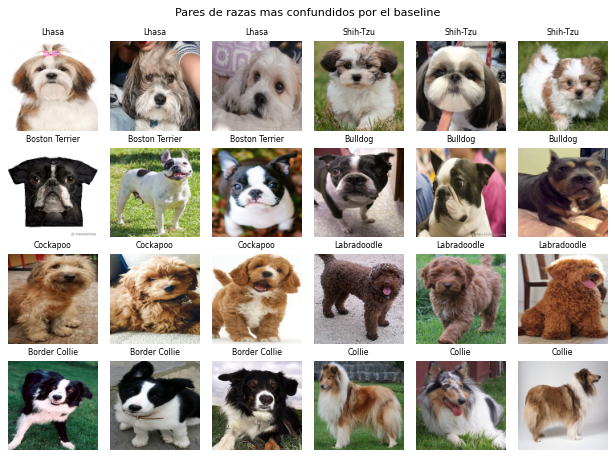

In [13]:
# Tres imagenes de cada raza de los cuatro pares mas confundidos.
paths, titles = [], []
for a, b in confusions.head(4)[["breed_a", "breed_b"]].itertuples(index=False):
    for breed in (a, b):
        pick = train_v1[train_v1["breed"] == breed].sample(3, random_state=SEED)
        paths += [DATASET / p for p in pick["path"]]
        titles += [breed[:16]] * 3
show_grid(paths, titles, cols=6, suptitle="Pares de razas mas confundidos por el baseline")
plt.show()

Los pares más confundidos son razas parecidas en tamaño, forma de la cabeza y pelaje, y varios son
variantes cercanas entre sí (las dos cruzas con caniche, Cockapoo y Labradoodle; los dos pastores belgas
y el alemán; las dos razas sin pelo). Son los pares que conviene incluir en el conjunto independiente
(sección 7) y mirar en el análisis de errores de la Etapa 2. En la prueba de la app de la Etapa 1, un Shiba
Inu de `test` se predijo como Dingo por el mismo motivo.

La grilla muestra además **ruido de etiqueta** que el filtrado automático no detecta: entre los Boston
Terrier hay una remera estampada (no es una foto de un perro) y algunos Bulldog se parecen más a un Boston
Terrier o a un Bulldog francés. Parte de la confusión medida entre esas razas viene de etiquetas dudosas,
no solo del parecido real.

### 5.4 Variaciones: iluminación, contenido de la escena, pose y fondo

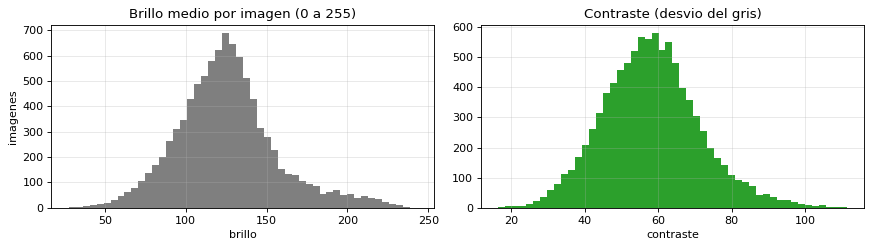

,count,mean,std,min,1%,50%,99%,max
brightness,9346.0,125.6,31.2,27.7,58.2,123.8,217.2,243.0
contrast,9346.0,58.2,13.3,16.5,29.8,57.8,94.3,111.3
blur_var,9346.0,1643.9,1891.9,24.7,91.1,1073.2,9236.2,36934.6


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(quality["brightness"], bins=50, color="tab:gray")
axes[0].set(title="Brillo medio por imagen (0 a 255)", xlabel="brillo", ylabel="imagenes")
axes[1].hist(quality["contrast"], bins=50, color="tab:green")
axes[1].set(title="Contraste (desvio del gris)", xlabel="contraste")
fig.tight_layout()
plt.show()
display(quality[["brightness", "contrast", "blur_var"]].describe(percentiles=[0.01, 0.5, 0.99]).round(1).T)

n_dogs,0,1,2,3 o mas
perros detectados,1510,7764,62,10


Imagenes con personas: 249 | con gatos y sin perro detectado: 220


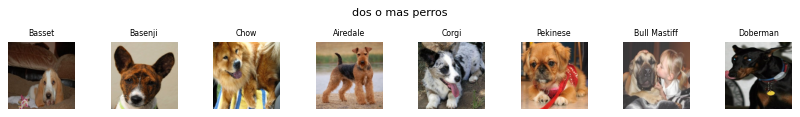

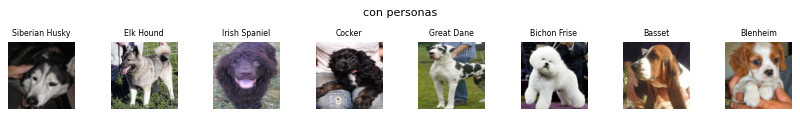

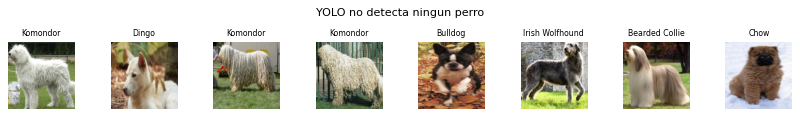

In [15]:
scene = pd.DataFrame(
    {
        "perros detectados": yolo["n_dogs"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3 o mas"}).value_counts().reindex(["0", "1", "2", "3 o mas"]),
    }
)
display(scene.T)
print("Imagenes con personas:", int((yolo["n_persons"] > 0).sum()), "| con gatos y sin perro detectado:", int(((yolo["n_cats"] > 0) & (yolo["n_dogs"] == 0)).sum()))

examples = {
    "dos o mas perros": yolo[yolo["n_dogs"] >= 2],
    "con personas": yolo[(yolo["n_persons"] > 0) & (yolo["n_dogs"] > 0)],
    "YOLO no detecta ningun perro": yolo[yolo["n_dogs"] == 0],
}
for label, frame in examples.items():
    sample = frame.sample(8, random_state=SEED)
    show_grid([DATASET / p for p in sample["path"]], [b[:16] for b in sample["breed"]], cols=8, suptitle=label)
    plt.show()

**Lectura.**

- **Iluminación**: el brillo medio va de imágenes muy oscuras a muy claras, pero los extremos son perros negros
  sobre fondo oscuro o blancos sobre fondo blanco, no fotos mal expuestas (se revisa en la sección 6). La
  augmentation agrega variaciones de brillo y contraste para cubrir fotos peor iluminadas que las del dataset.
- **Cantidad de perros**: casi todas las imágenes tienen un solo perro; las de dos o más son pocas (cachorros,
  parejas). En la Etapa 3 las escenas con varios perros van a ser frecuentes: el dataset no las representa.
- **Personas**: aparecen en una minoría de imágenes (dueños, exposiciones), en general parcialmente.
- **"Sin perro" según YOLO**: en las imágenes donde YOLO no detecta ningún perro sí hay un perro; son falsos
  negativos del detector (primeros planos, razas muy peludas como Komondor o Poodle, perros recortados). Por
  eso no se usa YOLO como regla automática de "sin perro visible" en el filtrado: descartaría imágenes buenas.
  También anticipa un límite de la Etapa 3: si YOLO no detecta al perro, el clasificador nunca lo ve.
- **Pose y fondo** (cualitativo, grillas de arriba): predominan poses de exposición (de perfil o de frente,
  parado o sentado), primeros planos de la cabeza y fondos de pasto, estudio o interiores; hay pocas
  oclusiones fuertes.

## 6. Control de calidad y filtrado

Las reglas son explícitas y reproducibles: las mediciones y las reglas están en `src/lib/dataset/quality.py`, y los
umbrales y el orden en que se aplican, en `src/lib/dataset/cleaning.py` (`CleaningConfig`). El mismo código genera los
splits con `scripts/build_splits.py`. La celda siguiente lo vuelve a correr sobre las mediciones de la sección 4.1 y
verifica que reproduce exactamente `data/splits/splits_v1.csv`.

Dónde se aplica cada regla:

- **Archivos corruptos y duplicados: en todos los splits.** Una imagen que no abre no sirve en ningún split, y una
  copia entre `train` y `valid`/`test` es fuga de datos.
- **Calidad (resolución, borrosidad, exposición): solo en `train`.** Si se filtraran `valid` y `test`, la evaluación
  sería más fácil que el uso real: la app va a recibir fotos borrosas o mal iluminadas, y conviene medir el sistema
  también con esas.
- Cada imagen se cuenta en un solo motivo, con esta prioridad: corrupta, después duplicado o fuga, después calidad.

In [16]:
from lib.dataset.cleaning import CleaningConfig, run_cleaning
from lib.dataset.quality import quality_flags

config = CleaningConfig()
cleaning = run_cleaning(v0, quality, embeddings, config)
assert cleaning.manifest.reset_index(drop=True).equals(load_manifest(SPLITS_DIR / "splits_v1.csv")), (
    "El filtrado no reproduce data/splits/splits_v1.csv"
)
print("El filtrado reproduce data/splits/splits_v1.csv")
print("Umbrales:", config.quality)
print("Criterio de duplicado:", config.duplicates)

SPLIT_ORDER = ["train", "valid", "test"]
drops = cleaning.drops
by_rule = (
    drops[drops["drop_reason"] != ""]
    .groupby(["drop_reason", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SPLIT_ORDER, fill_value=0)
)
by_rule["total"] = by_rule.sum(axis=1)
by_rule.loc["total"] = by_rule.sum()
display(by_rule)

El filtrado reproduce data/splits/splits_v1.csv
Umbrales: QualityThresholds(min_side=64, min_blur_var=30.0, min_brightness=15.0, max_brightness=250.0)
Criterio de duplicado: DuplicateCriterion(max_phash_distance=8, min_cosine_with_phash=0.9, min_cosine_alone=0.97)


split,train,valid,test,total
drop_reason,,,,
borrosa,5,0,0,5
duplicado dentro del split,447,6,6,459
etiqueta contradictoria,39,0,2,41
fuga entre splits,0,115,128,243
total,491,121,136,748


### 6.1 Archivos corruptos y resolución mínima

Antes de decidir qué se descarta, cuántas imágenes incumple cada regla de calidad en cada split (en `valid` y
`test` se miden pero no se descartan).

In [17]:
flags = quality_flags(quality, config.quality)
display(flags.groupby(quality["split"]).sum().T.reindex(columns=SPLIT_ORDER))
side = quality[["height", "width"]].min(axis=1)
print(f"Lado menor de las imagenes: minimo {side.min()}, maximo {side.max()} (umbral {config.quality.min_side})")

split,train,valid,test
corrupt,0,0,0
low_resolution,0,0,0
blurry,5,0,0
bad_exposure,0,0,0


Lado menor de las imagenes: minimo 224, maximo 224 (umbral 64)


### 6.2 Imágenes borrosas: varianza del Laplaciano

El Laplaciano responde a los bordes; una imagen nítida tiene muchos bordes marcados y su respuesta varía mucho, una
borrosa varía poco. La escala depende del contenido (un perro blanco y peludo sobre fondo claro tiene pocos bordes
aunque esté en foco), así que el umbral se elige mirando la distribución y ejemplos de cada lado, no con un valor
fijo de la literatura.

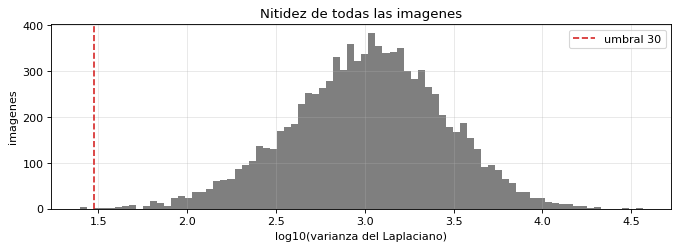

Percentiles de la varianza del Laplaciano: {0.001: 42.3, 0.01: 91.1, 0.05: 190.7, 0.5: 1073.2}


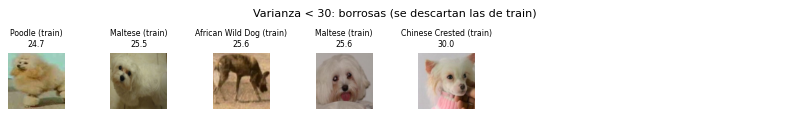

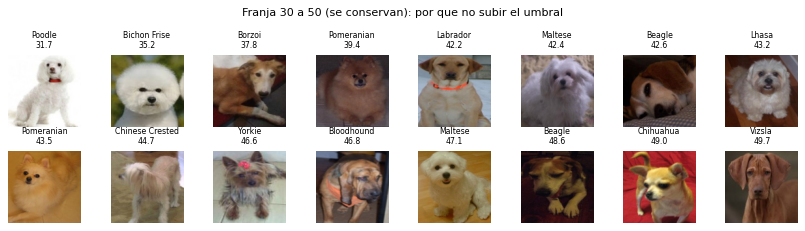

In [18]:
from lib.visualization.grid import show_grid

blur = quality["blur_var"]
threshold = config.quality.min_blur_var
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(np.log10(blur.clip(lower=1)), bins=80, color="tab:gray")
ax.axvline(np.log10(threshold), color="tab:red", ls="--", label=f"umbral {threshold:g}")
ax.set(xlabel="log10(varianza del Laplaciano)", ylabel="imagenes", title="Nitidez de todas las imagenes")
ax.legend()
plt.show()
print("Percentiles de la varianza del Laplaciano:", blur.quantile([0.001, 0.01, 0.05, 0.5]).round(1).to_dict())

below = quality[blur < threshold].sort_values("blur_var")
show_grid(
    [DATASET / p for p in below["path"]],
    [f"{b} ({s})\n{v:.1f}" for b, s, v in zip(below["breed"], below["split"], below["blur_var"])],
    cols=8,
    suptitle=f"Varianza < {threshold:g}: borrosas (se descartan las de train)",
)
plt.show()

frontier = quality[(blur >= threshold) & (blur < 50)].sample(16, random_state=SEED).sort_values("blur_var")
show_grid(
    [DATASET / p for p in frontier["path"]],
    [f"{b}\n{v:.1f}" for b, v in zip(frontier["breed"], frontier["blur_var"])],
    cols=8,
    suptitle="Franja 30 a 50 (se conservan): por que no subir el umbral",
)
plt.show()

### 6.3 Exposición extrema

Brillo medio de la imagen en escala de grises. Se miran los extremos para decidir si son fotos mal expuestas o
perros oscuros o claros sobre fondos del mismo tono.

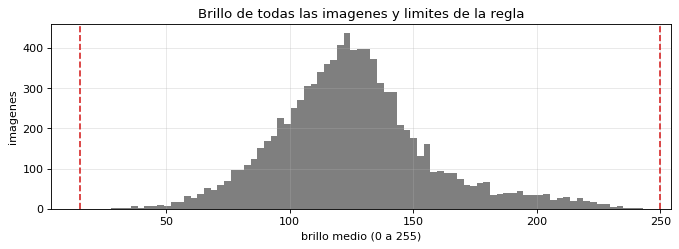

Brillo medio: minimo 27.7, maximo 243.0; limites 15 y 250


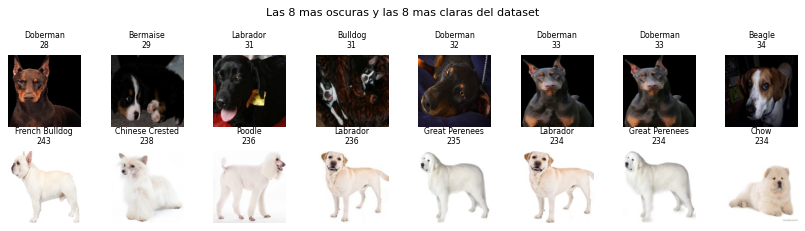

In [19]:
brightness = quality["brightness"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(brightness, bins=80, color="tab:gray")
for limit in (config.quality.min_brightness, config.quality.max_brightness):
    ax.axvline(limit, color="tab:red", ls="--")
ax.set(xlabel="brillo medio (0 a 255)", ylabel="imagenes", title="Brillo de todas las imagenes y limites de la regla")
plt.show()
print(f"Brillo medio: minimo {brightness.min():.1f}, maximo {brightness.max():.1f}; "
      f"limites {config.quality.min_brightness:g} y {config.quality.max_brightness:g}")

extremes = pd.concat([quality.nsmallest(8, "brightness"), quality.nlargest(8, "brightness")])
show_grid(
    [DATASET / p for p in extremes["path"]],
    [f"{b}\n{v:.0f}" for b, v in zip(extremes["breed"], extremes["brightness"])],
    cols=8,
    suptitle="Las 8 mas oscuras y las 8 mas claras del dataset",
)
plt.show()

### 6.4 Duplicados y casi-duplicados: pHash y embeddings

Dos señales complementarias:

- **pHash** (hash perceptual): reduce la imagen, aplica la DCT, se queda con las frecuencias bajas y las compara contra
  su mediana; dos imágenes son parecidas si sus hashes de 64 bits difieren en pocos bits (distancia de Hamming). Es
  barato y robusto a reescalado y compresión, pero no a recortes, zoom ni espejados.
- **Similitud coseno de los embeddings del baseline** (ResNet50 de la Etapa 1): captura la misma foto recortada, con
  zoom o con otro color, que el pHash no ve.

Se miden como candidatos los pares con pHash a distancia 12 o menos o con coseno de 0,93 o más (más amplio que el
criterio, para poder mirar la frontera), y se confirma como copia un par con **pHash a 8 o menos y coseno de 0,90 o
más, o con coseno de 0,97 o más**. La tabla cruza las dos medidas y separa los pares confirmados.

In [20]:
from lib.visualization.grid import show_pairs

pairs = cleaning.pairs.copy()
pairs["pHash"] = pd.cut(pairs["phash_distance"], [-1, 8, 12, 64], labels=["0 a 8", "9 a 12", "13 o mas"])
pairs["coseno"] = pd.cut(
    pairs["cosine"], [-1, 0.90, 0.95, 0.97, 1.01], right=False,
    labels=["< 0,90", "0,90 a 0,95", "0,95 a 0,97", ">= 0,97"],
)
confirmed_keys = set(zip(cleaning.confirmed["i"], cleaning.confirmed["j"]))
pairs["confirmado"] = [(i, j) in confirmed_keys for i, j in zip(pairs["i"], pairs["j"])]

print(f"Pares candidatos: {len(pairs)} | confirmados como copia: {pairs['confirmado'].sum()}")
display(pd.crosstab([pairs["coseno"]], [pairs["pHash"], pairs["confirmado"]]))

leaks = pairs[pairs["confirmado"] & (pairs["kind"] == "entre splits")]
only_embeddings = leaks["phash_distance"] > config.duplicates.max_phash_distance
print(f"Pares confirmados entre splits (fugas): {len(leaks)}; "
      f"{only_embeddings.sum()} solo los detectan los embeddings (pHash > {config.duplicates.max_phash_distance})")
display(pd.crosstab(pairs.loc[pairs["confirmado"], "kind"], pairs.loc[pairs["confirmado"], "same_breed"].map({True: "misma raza", False: "distinta raza"})))

Pares candidatos: 7672 | confirmados como copia: 866


pHash       0 a 8       9 a 12       13 o mas      
confirmado  False True   False True     False True 
coseno                                             
< 0,90          5     0    599     0        0     0
0,90 a 0,95     0    10     49     0     5428     0
0,95 a 0,97     0    33     18     0      707     0
>= 0,97         0   450      0   129        0   244

Pares confirmados entre splits (fugas): 301; 126 solo los detectan los embeddings (pHash > 8)


same_breed,distinta raza,misma raza
kind,,
dentro de test,1,10
dentro de train,24,517
dentro de valid,0,13
entre splits,0,301


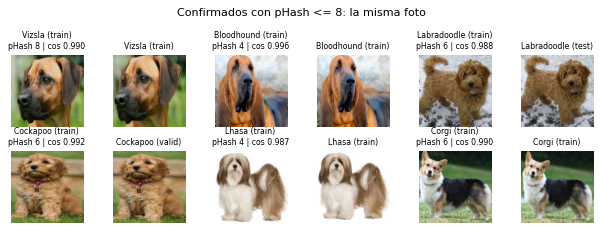

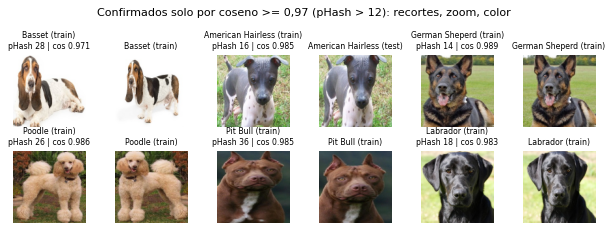

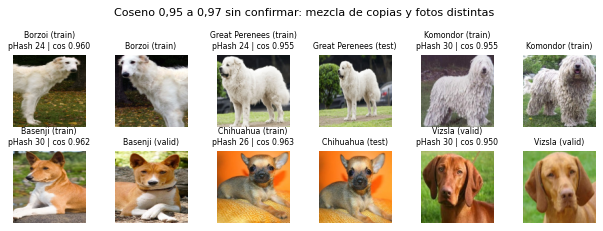

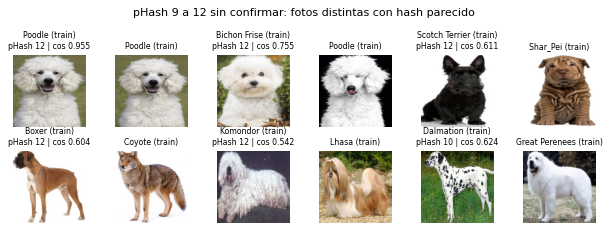

In [21]:
def sample(frame, n=6):
    return frame.sample(min(n, len(frame)), random_state=SEED)


by_phash = pairs[pairs["confirmado"] & (pairs["phash_distance"] <= 8)]
show_pairs(sample(by_phash), DATASET, suptitle="Confirmados con pHash <= 8: la misma foto")
plt.show()

by_cosine = pairs[pairs["confirmado"] & (pairs["phash_distance"] > 12)]
show_pairs(sample(by_cosine), DATASET, suptitle="Confirmados solo por coseno >= 0,97 (pHash > 12): recortes, zoom, color")
plt.show()

frontier_pairs = pairs[~pairs["confirmado"] & (pairs["cosine"] >= 0.95)]
show_pairs(sample(frontier_pairs), DATASET, suptitle="Coseno 0,95 a 0,97 sin confirmar: mezcla de copias y fotos distintas")
plt.show()

phash_only = pairs[~pairs["confirmado"] & pairs["phash_distance"].between(9, 12)]
show_pairs(sample(phash_only), DATASET, suptitle="pHash 9 a 12 sin confirmar: fotos distintas con hash parecido")
plt.show()

### 6.5 Etiqueta contradictoria

Si la misma foto aparece con dos razas distintas, no se puede saber cuál etiqueta es la correcta. Se descartan todas
las copias del grupo (en lugar de quedarse con una), porque conservar cualquiera agrega una etiqueta posiblemente
falsa.

Pares de la misma foto con dos razas: 25


,pares
American Spaniel / Irish Spaniel,8
Rhodesian / Vizsla,6
Blenheim / Japanese Spaniel,2
Border Collie / Collie,2
Cairn / Scotch Terrier,2
Lhasa / Shih-Tzu,2
Boston Terrier / Bulldog,1
Bulldog / French Bulldog,1
Cockapoo / Labradoodle,1


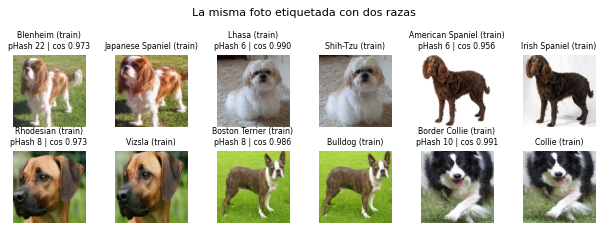

In [22]:
conflicts = pairs[pairs["confirmado"] & ~pairs["same_breed"]]
names = conflicts.apply(lambda r: " / ".join(sorted([r["breed_i"], r["breed_j"]])), axis=1)
print(f"Pares de la misma foto con dos razas: {len(conflicts)}")
display(names.value_counts().rename("pares").to_frame())
show_pairs(sample(conflicts), DATASET, suptitle="La misma foto etiquetada con dos razas")
plt.show()

### 6.6 Fugas entre splits y reposición de `valid` y `test`

De cada grupo de copias se conserva una sola imagen: la de `train` si hay (la fuga se quita de `valid`/`test` y la
imagen sigue sirviendo para entrenar). Como eso dejaba razas con muy pocas imágenes de evaluación, `valid` y `test`
se completaron hasta 10 por raza con imágenes de `train` sin ningún parecido (coseno menor a 0,95 con todo el
dataset), y las de `valid`/`test` con una casi-copia en otro split (coseno 0,95 a 0,97) pasaron a `train` (D-24 del
plan). La verificación de que no queda fuga está en la sección 10.

In [23]:
# Movimientos con signo: cada fila suma original - descartadas +/- movimientos = final.
s = cleaning.summary
near = pd.Series(s["moved_to_train_near_copies"]).reindex(["valid", "test"], fill_value=0)
refill = pd.Series(s["moved_from_train"]).reindex(["valid", "test"], fill_value=0)
moves = pd.DataFrame(
    {
        "original": pd.Series(s["original"]),
        "descartadas": -by_rule.drop(index="total")[SPLIT_ORDER].sum(),
        "casi-copias a train": pd.Series({"train": near.sum(), "valid": -near["valid"], "test": -near["test"]}),
        "reposicion desde train": pd.Series({"train": -refill.sum(), "valid": refill["valid"], "test": refill["test"]}),
        "final": pd.Series(s["final"]),
    }
).reindex(SPLIT_ORDER).astype(int)
assert (moves.drop(columns="final").sum(axis=1) == moves["final"]).all()
display(moves)
per_breed = cleaning.manifest.groupby(["breed", "split"]).size().unstack()[SPLIT_ORDER]
display(per_breed.agg(["min", "max"]))

,original,descartadas,casi-copias a train,reposicion desde train,final
train,7946,-491,102,-359,7198
valid,700,-121,-47,168,700
test,700,-136,-55,191,700


split,train,valid,test
min,56,10,10
max,185,10,10


### 6.7 Imágenes mal etiquetadas o sin perro visible

- **Sin perro visible**: no se filtra con YOLO. La sección 5.4 mostró que las imágenes donde YOLO no detecta perro
  sí tienen uno (falsos negativos del detector), así que la regla descartaría imágenes buenas.
- **Mal etiquetadas**: la única forma automática y confiable que encontramos es la etiqueta contradictoria (6.5).
  Hay ruido de etiqueta que no se puede detectar sin revisar a mano (por ejemplo, la remera estampada entre los
  Boston Terrier de la sección 5.3) y queda como limitación del dataset. No se usa el error del modelo para
  descartar imágenes: eso dejaría solo las fáciles y sesgaría las métricas.

**Lectura.**

- **Se descartan 748 de 9.346 imágenes**, casi todas por duplicados: 459 copias dentro de un mismo split, 243 fugas
  (115 de `valid` y 128 de `test` que eran copias de `train`) y 41 por etiqueta contradictoria. La calidad pesa poco:
  5 borrosas y ninguna corrupta, de baja resolución o mal expuesta.
- **Corruptos y resolución**: todas abren y todas son de 224 x 224, así que estas reglas no descartan nada. Se
  dejan igual, porque el mismo código se usa con el conjunto independiente, donde sí hay tamaños variados.
- **Borrosidad**: con el umbral de 30 solo caen 5 imágenes, todas de `train`. Es un umbral bajo a propósito: entre 30
  y 50 casi todas las imágenes son nítidas, pero de perros blancos y peludos o de pelaje oscuro sobre fondos lisos,
  con pocos bordes. Un umbral más alto descartaría sobre todo a esas razas. Incluso entre las 5 descartadas hay 4
  perros blancos y peludos: el Laplaciano mezcla nitidez con textura, así que la regla se usa solo para el extremo
  y se acepta su imprecisión (afecta a 5 de 7.946 imágenes de `train`).
- **Exposición**: los extremos (brillo medio de 27,7 a 243) son Dobermans y Labradores negros sobre fondo oscuro y
  perros blancos sobre fondo blanco, no fotos mal expuestas. Los límites de 15 y 250 no descartan ninguna: la regla
  queda escrita y documentada, pero en este dataset no corresponde aplicarla.
- **Duplicados**: el pHash solo no alcanza. De las 301 fugas confirmadas entre splits, 126 solo las detectan los
  embeddings: son la misma foto recortada, con zoom o con otro color, que cambia el hash. A la inversa,
  un pHash parecido sin coseno alto (pHash de 9 a 12 con coseno menor a 0,90) corresponde a fotos distintas con
  fondos o composición parecidos, por eso el pHash cercano necesita la confirmación del coseno.
- **La frontera de 0,95 a 0,97** mezcla copias reales (la misma foto recortada o espejada) con fotos distintas de
  la misma raza, por eso el umbral de copia confirmada es 0,97. Las casi-copias de esa franja que estaban en
  `valid` o `test` se pasaron a `train` (6.6): no se cuentan como duplicado, pero tampoco se evalúa con ellas.
- **Etiqueta contradictoria**: 25 pares de la misma foto con dos razas, casi todos entre razas parecidas (American e
  Irish Spaniel, Rhodesian y Vizsla, Blenheim y Japanese Spaniel, Lhasa y Shih-Tzu). Son los mismos pares que el EDA
  marcó como confundibles: parte de esa confusión viene de etiquetas que ni el propio dataset tiene claras.
- **Resultado**: `train` queda con 7.198 imágenes (56 a 185 por raza) y `valid` y `test` con 700 cada uno, 10 por
  raza. Sin la reposición, el 18 % de `test` eran copias de `train` y cualquier métrica sobre los splits
  originales sale inflada.

## 7. Conjunto independiente de evaluación

TO-DO: imágenes que no pertenezcan al dataset (internet o fotos propias), con las mismas razas que
las carpetas del dataset. Incluir imágenes con un perro (Etapas 1 y 2), escenas con varios perros u
otros objetos e imágenes sin perros (Etapa 3). Documentar fuente y licencia; no subirlas al repositorio.

In [24]:
## TO-DO: construcción y resumen del conjunto independiente (por ejemplo, en data/dataset/independent/<raza>/).

## 8. Preprocesamiento

Un único pipeline, en `src/lib/vision/preprocessing.py`, que usan las notebooks, el entrenamiento, la evaluación y los
servicios de la app (enunciado 3.5). Recibe la imagen como la entrega la app (BGR uint8, convención de OpenCV) y
devuelve el arreglo que espera el modelo:

1. **BGR a RGB**: OpenCV lee en BGR; los pesos preentrenados de torchvision esperan RGB.
2. **Resize conservando la proporción**: el lado mayor pasa a `IMAGE_SIZE` (224).
3. **Normalización con la media y el desvío de ImageNet**, los mismos con que se entrenaron los pesos (se verifica
   abajo contra `ResNet50_Weights.IMAGENET1K_V1.transforms()`).
4. **Padding hasta un cuadrado de 224**, centrado, con ceros después de normalizar: equivale a rellenar con la media
   de ImageNet (un gris neutro), que es lo mismo que hace el padding de las convoluciones.
5. **Orden CHW**, el que usa PyTorch.

Por qué padding y no las otras opciones (D-03 del plan): las CNN no son invariantes a la relación de aspecto. **Estirar**
deforma al perro (un recorte de YOLO de un perro acostado queda achatado y puede cambiar la raza aparente) y **recortar
al centro** descarta los bordes (en un recorte alargado se pierde la cabeza o las patas). El padding conserva todo. Es
un desvío respecto de Class 1 (celda 108), que usa `Resize((224, 224))`: en este dataset no cambia nada, porque todas
las imágenes son cuadradas de 224, pero sí en los recortes de YOLO y las fotos de los usuarios, que es donde importa.

Como todas las imágenes del dataset son cuadradas, la diferencia se muestra con la imagen más alargada del conjunto
independiente.

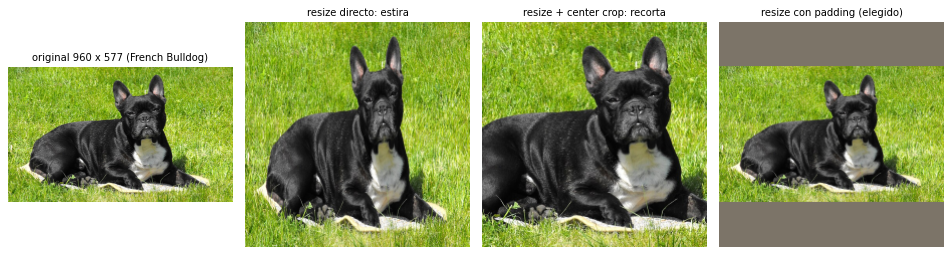

In [25]:
import cv2

from lib.dataset.independent import load_registry
from lib.vision.preprocessing import IMAGENET_MEAN, IMAGENET_STD, denormalize_image, preprocess_image

S = settings.image_size
registry = load_registry(SPLITS_DIR / "independent_v1.csv")
shapes = [cv2.imread(str(DATASET / p)).shape[:2] for p in registry["path"]]
aspect = [max(h, w) / min(h, w) for h, w in shapes]
example = registry.iloc[int(np.argmax(aspect))]
bgr = cv2.imread(str(DATASET / example["path"]))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]

stretched = cv2.resize(rgb, (S, S), interpolation=cv2.INTER_AREA)
scale = S / min(h, w)
covered = cv2.resize(rgb, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
top, left = (covered.shape[0] - S) // 2, (covered.shape[1] - S) // 2
center_crop = covered[top : top + S, left : left + S]
padded = denormalize_image(preprocess_image(bgr, S))

show_grid(
    [rgb, stretched, center_crop, padded],
    [f"original {w} x {h} ({example['breed']})", "resize directo: estira", "resize + center crop: recorta", "resize con padding (elegido)"],
    cols=4, cell_inches=3.0, title_fontsize=9,
)
plt.show()

In [26]:
from torchvision.models import ResNet50_Weights
from torchvision.transforms import functional as TF

x = preprocess_image(bgr, S)
padding = np.all(x == 0, axis=0)
print(f"Salida: forma {x.shape}, tipo {x.dtype}; padding: {padding.mean():.1%} de los pixeles, todos en 0")

# Normalizacion: la del modulo contra la de los pesos preentrenados.
weights_t = ResNet50_Weights.IMAGENET1K_V1.transforms()
print("Media y desvio del modulo iguales a los de IMAGENET1K_V1:",
      np.allclose(weights_t.mean, IMAGENET_MEAN) and np.allclose(weights_t.std, IMAGENET_STD))

# Orden de canales: con una imagen del dataset (ya es de 224, no hay resize) el modulo tiene que dar lo mismo
# que torchvision sobre la imagen convertida a RGB, y distinto si se le pasa BGR sin convertir.
square = cv2.imread(str(DATASET / v0["path"].iloc[0]))
reference = TF.normalize(TF.to_tensor(cv2.cvtColor(square, cv2.COLOR_BGR2RGB)), weights_t.mean, weights_t.std).numpy()
without_conversion = TF.normalize(TF.to_tensor(square), weights_t.mean, weights_t.std).numpy()
print(f"Diferencia maxima con torchvision en RGB: {np.abs(preprocess_image(square, S) - reference).max():.2e}")
print(f"Diferencia maxima si se olvida BGR a RGB: {np.abs(preprocess_image(square, S) - without_conversion).max():.2f}")

Salida: forma (3, 224, 224), tipo float32; padding: 39.7% de los pixeles, todos en 0
Media y desvio del modulo iguales a los de IMAGENET1K_V1: True
Diferencia maxima con torchvision en RGB: 0.00e+00
Diferencia maxima si se olvida BGR a RGB: 2.91


In [27]:
import inspect

import lib.dataset.augmentation as augmentation_module
import lib.models.baseline as baseline_module
import lib.services.classifier_service as classifier_module
import lib.services.detection_service as detection_module
import lib.vision.preprocessing as preprocessing

uses = {
    "Etapa 1, extract_embedding (baseline)": baseline_module.preprocess_batch is preprocessing.preprocess_batch,
    "Etapa 2, entrenamiento y evaluacion (make_transform)": augmentation_module.preprocess_image is preprocessing.preprocess_image,
    "Etapa 2, extract_custom_embedding": "lib.vision.preprocessing" in inspect.getsource(classifier_module.ClassifierService.extract_custom_embedding),
    "Etapa 3, classify_detected_dog": detection_module.preprocess_batch is preprocessing.preprocess_batch,
}
display(pd.Series(uses, name="usa lib/vision/preprocessing.py").to_frame())

C:\Users\lucas\Documents\TUIA\IA 5.1 - Vision por Computadora\cv2-venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,usa lib/vision/preprocessing.py
"Etapa 1, extract_embedding (baseline)",True
"Etapa 2, entrenamiento y evaluacion (make_transform)",True
"Etapa 2, extract_custom_embedding",True
"Etapa 3, classify_detected_dog",True


**Lectura.**

- **Padding contra las alternativas**: con el French Bulldog acostado (960 x 577), estirar lo deforma (queda más alto y con el cuerpo comprimido) y el recorte al centro le corta parte del cuerpo y las patas. Con padding se conserva entero; el costo es que el perro ocupa menos de la imagen (el 39,7 % de los píxeles son relleno). Para los modelos preentrenados, que vieron perros que llenan el encuadre, es un desajuste leve, y el fine-tuning lo compensa porque entrena con el mismo pipeline.
- **El relleno vale exactamente 0 después de normalizar**, es decir, la media de ImageNet: no introduce bordes ni texturas falsas.
- **Normalización y canales verificados**: la media y el desvío del módulo coinciden con los de los pesos `IMAGENET1K_V1`, y sobre una imagen del dataset el módulo da exactamente lo mismo que torchvision sobre la imagen en RGB (diferencia 0). Si se olvidara la conversión de BGR a RGB, la entrada cambiaría hasta 2,9 desvíos: es el error más frecuente que señala el enunciado y no da ningún error al ejecutar, solo peores predicciones.
- **Un solo camino**: la Etapa 1, el entrenamiento y la evaluación, `extract_custom_embedding` y la Etapa 3 usan las mismas funciones de `lib/vision/preprocessing.py`, así que lo que se mide en las notebooks es lo que hace la app.
- **CNN propia (Modelo B)**: usa también la normalización de ImageNet, para no tener dos pipelines. El experimento con estadísticas calculadas sobre `train` (tabla de experimentos de `2-train.ipynb`) dio una diferencia de 0,4 puntos de accuracy en `valid`, dentro del ruido: la BatchNorm después de la primera convolución absorbe la diferencia.

## 9. Data augmentation

Online, con Albumentations (ya está en el `requirements.txt` provisto y trabaja con arreglos de NumPy, como OpenCV), en
`src/lib/dataset/augmentation.py`. Se aplica **solo a `train`**, en cada época y sobre la imagen BGR original; después
la imagen pasa por el mismo preprocesamiento de la sección 8. `valid`, `test`, el conjunto independiente y la app
usan solo el preprocesamiento.

| Transformación | Rango | Probabilidad | Por qué |
|---|---|---|---|
| Recorte desde los bordes | hasta 15 % de cada lado, independiente por lado | 0,5 | Simula los recortes de YOLO de la Etapa 3: más ajustados que el encuadre del dataset y con otra relación de aspecto (sección 4.2) |
| Flip horizontal | | 0,5 | Un perro mirando a la izquierda sigue siendo de la misma raza |
| Rotación | +-12 grados, relleno con la media de ImageNet | 0,4 | Cámara inclinada; el relleno vale 0 al normalizar, igual que el padding |
| Brillo y contraste | +-20 % | 0,5 | Iluminación distinta (la sección 5.4 mostró variedad, pero no fotos mal expuestas) |
| Desenfoque gaussiano | sigma 0,3 a 1,2 | 0,15 | Fotos de celular, movimiento |
| Ruido gaussiano | desvío 2 % a 6 % del rango | 0,15 | Poca luz, compresión |

Excluidas: **flip vertical y rotaciones de 90 grados** (los perros no aparecen cabeza abajo; Class_2_lab los usa
porque las imágenes satelitales no tienen "arriba") y **cambios fuertes de tono o saturación** (el color del pelaje
distingue razas: un Vizsla y un Rhodesian se diferencian en parte por el tono). Las probabilidades son moderadas
para que la mayoría de las imágenes conserve el aspecto del dataset.

AugmentationConfig(crop_border=0.15, crop_p=0.5, hflip_p=0.5, rotate_degrees=12.0, rotate_p=0.4, brightness=0.2, contrast=0.2, color_p=0.5, blur_sigma=(0.3, 1.2), blur_p=0.15, noise_std=(0.02, 0.06), noise_p=0.15)


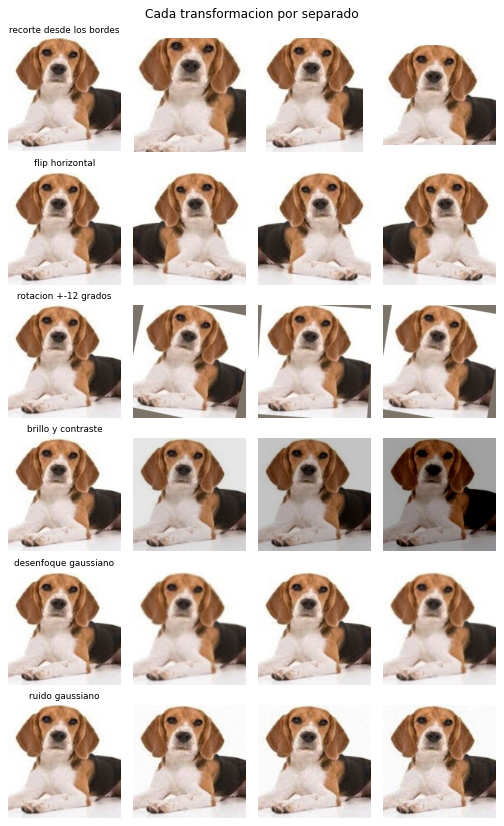

In [28]:
from lib.dataset.augmentation import (
    AugmentationConfig, augmentation_examples, make_transform, single_transform_examples,
)

aug_config = AugmentationConfig()
print(aug_config)
sample_row = v1[(v1["split"] == "train") & (v1["breed"] == "Beagle")].iloc[0]
sample_bgr = cv2.imread(str(DATASET / sample_row["path"]))
to_rgb = lambda img: cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Cada transformacion sola, siempre aplicada, con su rango: original y tres muestras por fila.
images, titles = [], []
for name, examples in single_transform_examples(sample_bgr, aug_config, n=3, seed=SEED).items():
    images += [to_rgb(sample_bgr)] + [to_rgb(e) for e in examples]
    titles += [name] + [""] * len(examples)
show_grid(images, titles, cols=4, cell_inches=1.6, title_fontsize=8, suptitle="Cada transformacion por separado")
plt.show()

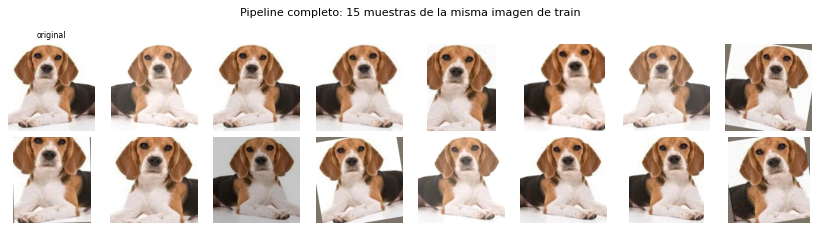

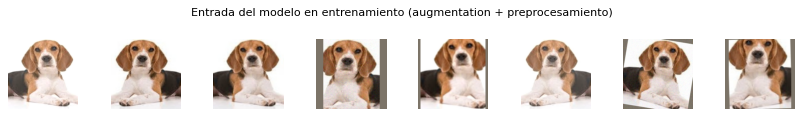

In [29]:
# El pipeline completo (con sus probabilidades) sobre la misma imagen.
examples = augmentation_examples(sample_bgr, 15, aug_config, seed=SEED)
show_grid([to_rgb(sample_bgr)] + [to_rgb(e) for e in examples], ["original"] + [""] * 15, cols=8,
          suptitle="Pipeline completo: 15 muestras de la misma imagen de train")
plt.show()

# Lo que recibe el modelo: augmentation y despues el preprocesamiento compartido (con su padding).
train_transform = make_transform(train=True, image_size=S, config=aug_config, seed=SEED)
show_grid([denormalize_image(train_transform(sample_bgr)) for _ in range(8)], cols=8,
          suptitle="Entrada del modelo en entrenamiento (augmentation + preprocesamiento)")
plt.show()

In [30]:
from lib.training.trainer import train as train_function

eval_transform = make_transform(train=False, image_size=S)
print("valid/test: sin augmentation (igual al preprocesamiento):",
      np.array_equal(eval_transform(sample_bgr), preprocess_image(sample_bgr, S)))
print("valid/test: determinista:", np.array_equal(eval_transform(sample_bgr), eval_transform(sample_bgr)))
print("train: cambia en cada llamada:", not np.array_equal(train_transform(sample_bgr), train_transform(sample_bgr)))
source = inspect.getsource(train_function)
print("El entrenamiento usa make_transform(train=False) para valid:",
      'manifest, "valid"' in source and "make_transform(train=False" in source)

valid/test: sin augmentation (igual al preprocesamiento): True
valid/test: determinista: True
train: cambia en cada llamada: True
El entrenamiento usa make_transform(train=False) para valid: True


**Semillas: un problema encontrado y resuelto.** `A.Compose(seed=s)` de Albumentations 2.0.8 le pasa la misma
semilla a todas las transformaciones, y las que tienen igual probabilidad quedan correlacionadas: por ejemplo, el
recorte y el flip (las dos con p = 0,5) se aplicarían siempre juntos. `seed_pipeline` le da a cada transformación una
semilla distinta derivada de la semilla global (`np.random.SeedSequence`), y el resultado sigue siendo reproducible.
La celda lo mide con dos flips de p = 0,5: si fueran independientes, en la mitad de las llamadas se aplicaría uno solo
y la imagen quedaría espejada.

In [31]:
import albumentations as A

from lib.dataset.augmentation import seed_pipeline

probe = np.arange(12, dtype=np.uint8).reshape(2, 2, 3)


def single_flip_rate(pipeline, n=200):
    return np.mean([not np.array_equal(pipeline(image=probe)["image"], probe) for _ in range(n)])


same_seed = A.Compose([A.HorizontalFlip(p=0.5), A.HorizontalFlip(p=0.5)], seed=SEED)
own_seeds = A.Compose([A.HorizontalFlip(p=0.5), A.HorizontalFlip(p=0.5)])
seed_pipeline(own_seeds, SEED)
print(f"Fraccion de llamadas con un solo flip: Compose(seed) {single_flip_rate(same_seed):.2f} | "
      f"seed_pipeline {single_flip_rate(own_seeds):.2f} (independientes: 0,50)")

Fraccion de llamadas con un solo flip: Compose(seed) 0.00 | seed_pipeline 0.52 (independientes: 0,50)


**Desbalance.** La augmentation no corrige el desbalance de `train` (56 a 185 imágenes por raza): genera variantes
de todas las imágenes por igual, sin cambiar cuántas ve la red de cada raza. Para eso se compararon pesos de clase en
la loss (inversos a la frecuencia) en la tabla de experimentos del Modelo A, en `2-train.ipynb` (D-25).

**Lectura.**

- **Cada transformación conserva la raza**: en la grilla por separado el perro sigue siendo reconocible en todas. El desenfoque y el ruido casi no se notan a este tamaño, a propósito: imitan fotos de celular, no imágenes dañadas.
- **El recorte desde los bordes cumple su función**: en la entrada del modelo aparecen perros recortados con bandas de padding, el mismo aspecto que van a tener los recortes de YOLO en la Etapa 3. Es la transformación que más acerca el entrenamiento al dominio de uso.
- **Solo en `train`**: la transformación de evaluación es igual al preprocesamiento y es determinista, la de entrenamiento cambia en cada llamada, y el código de entrenamiento construye `valid` con `make_transform(train=False)`.
- **Semillas**: con la semilla de `A.Compose` los dos flips se aplicaron siempre juntos (0 % de llamadas con un solo flip); con `seed_pipeline`, 52 %, lo esperado para transformaciones independientes. Sin la corrección, el recorte y el flip habrían quedado acoplados en todo el entrenamiento sin dar ningún error.
- **Intensidad**: el experimento del Modelo B con augmentation más fuerte (recortes de hasta 25 %, rotación de 20 grados) rindió peor en `valid` con el mismo presupuesto de épocas (`2-train.ipynb`), lo que respalda rangos moderados.

## 10. Splits

Se parte de los splits del dataset y se corrigen sus fugas (sección 6 y D-24 del plan): `train` es la galería de la
Etapa 1 y el conjunto de entrenamiento; `valid` elige épocas, hiperparámetros y umbrales; `test` se mira una sola vez
por modelo final. Los splits quedan guardados en `data/splits/` (CSV con ruta, raza y split) y los regenera
`scripts/build_splits.py` con semilla 42. Las celdas verifican lo que pide el enunciado (3.7): ninguna imagen en dos
splits, ninguna casi-copia entre splits y ninguna consulta de la Etapa 1 indexada en la galería.

In [32]:
v1 = load_manifest(SPLITS_DIR / "splits_v1.csv", dataset_path=DATASET, check_files=True)
per_breed = v1.groupby(["split", "breed"]).size().groupby("split").agg(["min", "median", "max"])
split_table = v1.groupby("split").agg(imagenes=("path", "size"), razas=("breed", "nunique")).join(per_breed)
split_table.columns = ["imagenes", "razas", "min por raza", "mediana por raza", "max por raza"]
display(split_table.reindex(SPLIT_ORDER))

,imagenes,razas,min por raza,mediana por raza,max por raza
split,,,,,
train,7198,70,56,101.5,185
valid,700,70,10,10.0,10
test,700,70,10,10.0,10


In [33]:
from lib.dataset.cleaning import phash_array
from lib.dataset.quality import embedding_pairs, phash_pairs

assert v1["path"].is_unique
idx = row_of.loc[v1["path"]].to_numpy()  # filas de las mediciones de la seccion 4.1
split_v1 = v1["split"].to_numpy()

near = embedding_pairs(embeddings[idx], config.isolation_cosine)
near_cross = near[split_v1[near["i"]] != split_v1[near["j"]]]
hashes = phash_pairs(phash_array(quality)[idx], config.duplicates.max_phash_distance)
hashes_cross = hashes[split_v1[hashes["i"]] != split_v1[hashes["j"]]]

e = embeddings[idx] / np.linalg.norm(embeddings[idx], axis=1, keepdims=True)
max_cos = {
    f"{a} contra {b}": float((e[split_v1 == a] @ e[split_v1 == b].T).max())
    for a, b in [("valid", "train"), ("test", "train"), ("test", "valid")]
}
print("Imagenes en mas de un split: 0 (cada ruta aparece una vez)")
print(f"Pares entre splits con coseno >= {config.isolation_cosine}: {len(near_cross)}")
print(f"Pares entre splits con pHash <= {config.duplicates.max_phash_distance}: {len(hashes_cross)}")
print("Coseno maximo entre splits:", {k: f"{v:.5f}" for k, v in max_cos.items()})
gallery, queries = set(v1.loc[v1["split"] == "train", "path"]), set(v1.loc[v1["split"] == "test", "path"])
print("Consultas de la Etapa 1 (test) indexadas en la galeria (train):", len(gallery & queries))

Imagenes en mas de un split: 0 (cada ruta aparece una vez)
Pares entre splits con coseno >= 0.95: 0
Pares entre splits con pHash <= 8: 0
Coseno maximo entre splits: {'valid contra train': '0.94995', 'test contra train': '0.94997', 'test contra valid': '0.94944'}
Consultas de la Etapa 1 (test) indexadas en la galeria (train): 0


In [34]:
import json

files = []
for f in sorted(SPLITS_DIR.iterdir()):
    rows = len(pd.read_csv(f)) if f.suffix == ".csv" else None
    files.append({"archivo": f.name, "filas": rows, "KB": round(f.stat().st_size / 1024, 1)})
display(pd.DataFrame(files).set_index("archivo"))
print("Semilla:", config.seed, "| razas apartadas para calibrar el umbral de la Etapa 1:",
      json.loads((SPLITS_DIR / "calibration_breeds_v1.json").read_text()))

,filas,KB
archivo,,
calibration_breeds_v1.json,NaN,0.1
cleaning_summary_v1.json,NaN,1.4
dropped_v1.csv,748.0,46.3
independent_v1.csv,81.0,19.0
splits_v0.csv,9346.0,374.2
splits_v1.csv,8598.0,345.1


Semilla: 42 | razas apartadas para calibrar el umbral de la Etapa 1: ['Basenji', 'Basset', 'Corgi', 'Irish Spaniel', 'Malinois', 'Rhodesian', 'Siberian Husky']


**Lectura.**

- **Splits finales**: `train` con 7.198 imágenes (56 a 185 por raza, mediana 101,5) y `valid` y `test` con 700 cada uno, exactamente 10 por raza, las 70 razas en los tres.
- **Sin fuga**: ninguna imagen aparece en dos splits, no queda ningún par entre splits con coseno de 0,95 o más ni con pHash a distancia 8 o menos. El coseno máximo entre splits queda apenas por debajo de 0,95, el límite que se usó para elegir las imágenes repuestas: el corte se respetó.
- **Etapa 1**: ninguna consulta de `test` está en la galería (`train`), así que el NDCG@10 no sale inflado por imágenes indexadas.
- **Reproducibles**: semilla 42; `splits_v1.csv` (8.598 filas) más los descartes con su motivo (`dropped_v1.csv`, 748 filas), el resumen de la limpieza y las 7 razas apartadas para calibrar el umbral de la Etapa 1. `splits_v0.csv` son los splits originales del dataset, guardados para comparar.
- **Limitación**: las imágenes repuestas en `valid` y `test` se eligieron entre las que no tienen ningún parecido en el dataset (27 % de `test`). Eso puede sesgarlos levemente hacia fotos menos típicas o que no vienen en series de una misma sesión.

## 11. Resumen final

TO-DO: tabla con la cantidad de razas e imágenes por split, incluido el conjunto independiente.

In [35]:
## TO-DO: tabla resumen.

## 12. Licencias y uso de imágenes

TO-DO: licencia del dataset, fuente y licencia de las imágenes del conjunto independiente y criterio
aplicado a imágenes con personas identificables.